In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.ExperimentSet import ExperimentSet
from src.Retrieval import Retrieval

In [3]:
EXPERIMENT_SET = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08'
V08 = ExperimentSet(EXPERIMENT_SET)
V08.set_retrieval_list()
V08.load_retrievals(iteration=-1)

In [4]:
brf_ths = {
    'DF': 0.120,
    'CF': 0.076,
    'BF': 0.054,
    'AF': 0.044,
    'AN': 0.040,
    'AA': 0.045,
    'BA': 0.052,
    'CA': 0.068,
    'DA': 0.092
}
for rpath in V08.retrievals:
    r = V08.retrievals[rpath]
    r.add_threshold_mask(r.obs, 'MISR', 'threshold_mask', 'brf', brf_ths)

In [5]:
def misr_S_1(y):
    return np.diag(1 / (0.04 * y)**2)
mask_conds = {
    # 'tau0.3mask': (1, 1),
    'threshold_mask': (1, 1),
    'ray_containment': (2, 2)
}
chi2 = V08.chi2(misr_S_1, variable='I', mask_conds=mask_conds)
chi2

,chi2
retrieval,
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/LCL_CTH,10.871575
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained,12.489859
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained_darksurf,10.372845
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/HBC/periodic,20.778908
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p150,8.661792
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p250,17.347160
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix22,10.395386
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix54,11.470972
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/fast,13.047756


In [9]:
ext_th = [0.3, np.inf]
tau_th = [0.3, np.inf]
stats = V08.cloud_stats(0.67, 'cloud', extinction_th=ext_th, tau_th=tau_th)
ref_key = Path('/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/default')
compare = V08.compare_to(ref_key, 0.67, 'cloud', extinction_th=ext_th, tau_th=tau_th)
table = pd.merge(compare, stats, on='retrieval')
table = pd.merge(table, chi2, on='retrieval')

ext_th_all = [0, np.inf]
tau_th_all = [0, np.inf]
stats_all = V08.cloud_stats(0.67, 'cloud', extinction_th=ext_th_all, tau_th=tau_th_all)
ref_key = Path('/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/default')
compare_all = V08.compare_to(ref_key, 0.67, 'cloud', extinction_th=ext_th_all, tau_th=tau_th_all)
table_all = pd.merge(compare_all, stats_all, on='retrieval')
table_all = pd.merge(table_all, chi2, on='retrieval')

In [10]:
table

,relative bias,relative difference,cloud fraction,tau bar,volume,cloudy voxel count,min extinction,q5,q25,q50,q75,q95,max extinction,mean extinction,std extinction,chi2
retrieval,,,,,,,,,,,,,,,,
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/LCL_CTH,0.120333,0.337868,0.16733727810650886,2.066429954063104,13.211687500000004,1747,0.308571,0.643619,2.583174,5.394752,10.942128,26.451847,66.645166,8.362713,8.510878,10.871575
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained,21.124243,3.068575,0.18461538461538463,2.060186616551134,20.588906250000008,2926,0.303711,0.493055,1.547314,3.797167,8.100043,18.638761,69.897971,6.040523,6.645118,12.489859
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained_darksurf,49.033346,3.196247,0.22674556213017752,2.075117373971214,28.824468750000012,4085,0.300040,0.448910,1.313670,3.146613,7.094748,17.108990,68.658084,5.323646,6.123362,10.372845
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/HBC/periodic,-36.258206,2.266632,0.15550295857988167,1.4157179267412454,12.534843750000006,1712,0.300935,0.539192,1.801440,3.767709,7.157971,16.462332,34.624157,5.432983,5.289284,20.778908
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p150,10.997113,0.566892,0.21136094674556213,1.8137525607094735,16.289625000000004,2154,0.302214,0.600415,1.986028,4.399314,9.731236,25.404212,81.503991,7.519411,8.525953,8.661792
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p250,-9.293176,0.508302,0.13798816568047337,2.2703312311641217,10.655562500000004,1409,0.316198,0.737484,3.196905,6.548327,12.524659,28.473850,63.833102,9.393918,9.005752,17.347160
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix22,-1.597794,0.778471,0.17088757396449705,1.9887740882413436,14.4821875,1915,0.300439,0.817624,2.501938,4.996583,9.806850,23.282356,51.634662,7.498146,7.271218,10.395386
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix54,-6.222847,1.097436,0.1472189349112426,2.2000090934104177,10.776562500000004,1425,0.304469,0.616887,2.455184,5.788028,12.655659,32.762326,86.328630,9.602847,10.671737,11.470972
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/fast,-2.127001,3.449349,0.16662721893491125,2.028654334351273,10.980750000000002,1452,0.301204,0.681742,2.452713,5.385953,13.003645,33.778730,90.823477,9.835900,11.435951,13.047756


In [11]:
table_all

,relative bias,relative difference,cloud fraction,tau bar,volume,cloudy voxel count,min extinction,q5,q25,q50,q75,q95,max extinction,mean extinction,std extinction,chi2
retrieval,,,,,,,,,,,,,,,,
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/LCL_CTH,0.031397,0.313604,0.2657988165680473,1.347477303125211,18.293687500000008,2419,1.854714e-03,0.132292,0.939624,3.295056,8.538065,22.853847,66.645166,6.255548,7.999998,10.871575
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained,25.443131,2.983579,0.3569230769230769,1.124189287943285,30.639468750000006,4496,4.069005e-09,0.026951,0.537177,1.945792,5.672399,16.149781,69.897971,4.220710,5.948480,12.489859
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained_darksurf,54.089883,3.106400,0.4369230769230769,1.135790272783415,43.582687500000006,6350,3.018233e-07,0.020530,0.425834,1.585369,4.616711,14.476087,68.658084,3.670839,5.425329,10.372845
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/HBC/periodic,-32.436043,2.171170,0.33254437869822484,0.727450817560554,21.995531250000006,3047,4.242944e-05,0.053239,0.474059,1.527689,4.299632,12.834371,34.624157,3.354343,4.634055,20.778908
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p150,13.830265,0.528761,0.432189349112426,0.9430220635664657,28.503062500000006,3769,4.416180e-14,0.038122,0.460915,1.620944,5.326159,19.453675,81.503991,4.568740,7.303982,8.661792
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p250,-10.398851,0.465932,0.19715976331360946,1.6271719890387788,13.854500000000003,1832,3.888538e-07,0.088509,1.281861,4.243576,10.177397,25.278567,63.833102,7.398659,8.705222,17.347160
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix22,-1.314713,0.741882,0.277396449704142,1.2737660726837856,20.138937500000004,2663,1.835969e-11,0.086950,1.026399,3.042759,7.470427,19.768154,51.634662,5.605910,6.880683,10.395386
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix54,-6.203839,1.047498,0.24615384615384617,1.3643211344102013,16.463562500000005,2177,1.064074e-11,0.037483,0.672507,2.545235,8.199361,26.948961,86.328630,6.517657,9.631529,11.470972
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/fast,-1.444298,3.326936,0.285207100591716,1.2372560652953155,16.69043750000001,2207,1.708166e-13,0.103575,0.818584,2.524377,8.126268,28.478895,90.823477,6.755295,10.222068,13.047756


In [12]:
table_all - table

,relative bias,relative difference,cloud fraction,tau bar,volume,cloudy voxel count,min extinction,q5,q25,q50,q75,q95,max extinction,mean extinction,std extinction,chi2
retrieval,,,,,,,,,,,,,,,,
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/LCL_CTH,-0.088936,-0.024263,0.098462,-0.718953,5.082,672,-0.306717,-0.511326,-1.643550,-2.099696,-2.404062,-3.598000,0.0,-2.107165,-0.510880,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained,4.318888,-0.084996,0.172308,-0.935997,10.050562,1570,-0.303711,-0.466103,-1.010137,-1.851374,-2.427644,-2.488980,0.0,-1.819814,-0.696638,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/CVM/unconstrained_darksurf,5.056536,-0.089847,0.210178,-0.939327,14.758219,2265,-0.300040,-0.428380,-0.887836,-1.561244,-2.478036,-2.632903,0.0,-1.652808,-0.698033,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/HBC/periodic,3.822163,-0.095462,0.177041,-0.688267,9.460688,1335,-0.300893,-0.485953,-1.327380,-2.240020,-2.858339,-3.627961,0.0,-2.078640,-0.655229,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p150,2.833152,-0.038131,0.220828,-0.87073,12.213438,1615,-0.302214,-0.562293,-1.525113,-2.778370,-4.405077,-5.950537,0.0,-2.950670,-1.221971,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/0p250,-1.105675,-0.042370,0.059172,-0.643159,3.198937,423,-0.316198,-0.648975,-1.915044,-2.304751,-2.347262,-3.195283,0.0,-1.995260,-0.300530,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix22,0.283081,-0.036589,0.106509,-0.715008,5.65675,748,-0.300439,-0.730674,-1.475539,-1.953824,-2.336423,-3.514202,0.0,-1.892236,-0.390535,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/aerosol/mix54,0.019008,-0.049938,0.098935,-0.835688,5.687,752,-0.304469,-0.579404,-1.782677,-3.242793,-4.456298,-5.813364,0.0,-3.085189,-1.040208,0.0
/data/gdi/b/johntl3/LundstromPub2025/experiments/CAMP2Ex_RF17/V08/cloud_motion/fast,0.682703,-0.122413,0.11858,-0.791398,5.709688,755,-0.301204,-0.578167,-1.634129,-2.861576,-4.877377,-5.299836,0.0,-3.080605,-1.213883,0.0


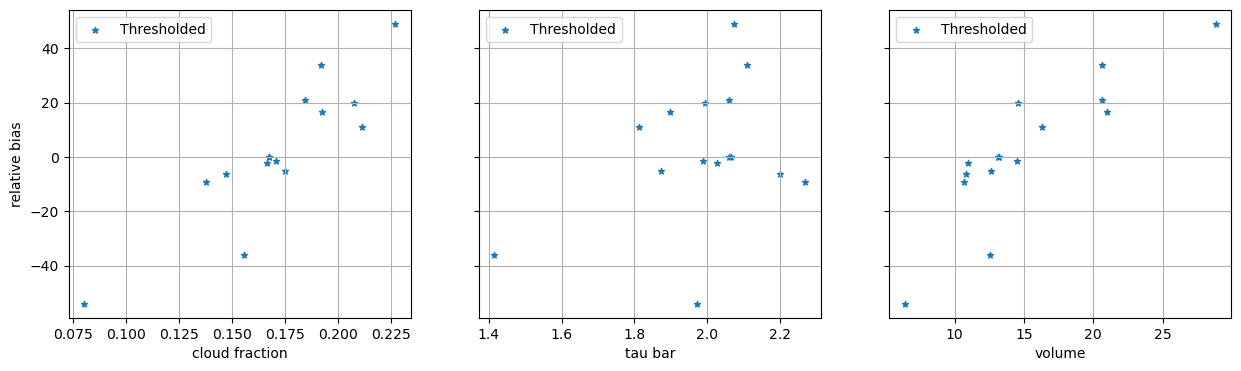

In [8]:
f, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
x = ['cloud fraction', 'tau bar', 'volume']
for i, a in enumerate(ax.flatten()):
    table.plot.scatter(x=x[i], y='relative bias', ax=a, marker='*', label='Thresholded')
    # table_all.plot.scatter(x=x[i], y='relative bias', ax=a, label='All')
    a.grid()
    a.legend()

# Threshold analysis

In [9]:
r = Retrieval(PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default')
r.load_retrieval()

In [10]:
ext_ths = np.linspace(0, 1, 21)
tau_ths = np.linspace(0, 1, 21)
volume = np.zeros((len(ext_ths), len(tau_ths)))
tau_bar = np.zeros((len(ext_ths), len(tau_ths)))
cf = np.zeros((len(ext_ths), len(tau_ths)))

for i, eth in enumerate(ext_ths):
    for j, tth in enumerate(tau_ths):
        stats = r.get_cloud_volume_stats(0.67, 'cloud', extinction_th=[eth, np.inf], tau_th=[tth, np.inf])
        volume[i,j] = stats['volume']
        tau_bar[i,j] = stats['tau bar']
        cf[i,j] = stats['cloud fraction']

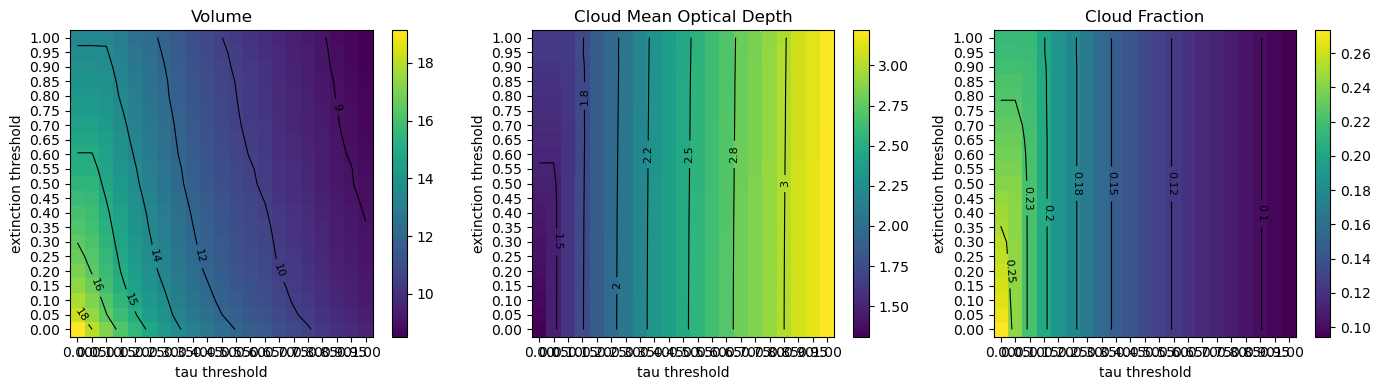

In [11]:
f, ax = plt.subplots(1, 3, figsize=(14,4))

# create coordinate grid matching array shape
X, Y = np.meshgrid(tau_ths, ext_ths)

titles = ['Volume', 'Cloud Mean Optical Depth', 'Cloud Fraction']
for i, data in enumerate([volume, tau_bar, cf]):
    # color background using pcolormesh (numeric axes)
    im = ax[i].pcolormesh(X, Y, data, shading='auto', cmap='viridis')
    # add contour lines on top
    cs = ax[i].contour(X, Y, data, colors='k', linewidths=0.8)
    ax[i].clabel(cs, inline=True, fontsize=8, fmt='%.2g')
    ax[i].set_title(titles[i])
    ax[i].set_xlabel('tau threshold')
    ax[i].set_ylabel('extinction threshold')
    ax[i].set_xticks(tau_ths)
    ax[i].set_yticks(ext_ths)
    plt.colorbar(im, ax=ax[i])

plt.tight_layout()
